In [3]:

from google.colab import files

uploaded = files.upload()


Saving student_marks_60.csv to student_marks_60 (1).csv
Saving customers_7.csv to customers_7 (1).csv


In [4]:

import pandas as pd

# Load both datasets
customers = pd.read_csv("customers_7.csv")
students = pd.read_csv("student_marks_60.csv")

# Display customer dataset
print("Customer Dataset:")
print(customers)

print("\nStudent Marks Dataset:")
print(students)


Customer Dataset:
  customer  visits_per_month  spend_rs_1000
0       P1               1.0            1.0
1       P2               1.5            2.0
2       P3               3.0            4.0
3       P4               5.0            7.0
4       P5               3.5            5.0
5       P6               4.5            5.0
6       P7               3.5            4.5

Student Marks Dataset:
   roll_no  theory_marks  practical_marks
0      S01          36.9             40.1
1      S02          35.1             48.9
2      S03          80.2             86.3
3      S04          41.8             38.8
4      S05          89.2             79.4
5      S06          62.9             72.1
6      S07          37.4             42.9
7      S08          56.5             71.0
8      S09          38.9             40.9
9      S10          85.4             85.4
10     S11          53.3             66.1
11     S12          60.3             77.0
12     S13          39.9             39.9
13     S14        

In [5]:

# Select features for K-Means clustering
X = customers[["visits_per_month", "spend_rs_1000"]].values

# Set the number of clusters
K = 2

# Select P1 and P4 as initial centroids
initial_centroids = X[[0, 3]].copy()

# Display selected features
print("Selected Features:")
print(X)

print("\nNumber of Clusters (K):", K)

# Display initial centroids
print("\nInitial Centroids:")
print("C1 (P1):", initial_centroids[0])
print("C2 (P4):", initial_centroids[1])


Selected Features:
[[1.  1. ]
 [1.5 2. ]
 [3.  4. ]
 [5.  7. ]
 [3.5 5. ]
 [4.5 5. ]
 [3.5 4.5]]

Number of Clusters (K): 2

Initial Centroids:
C1 (P1): [1. 1.]
C2 (P4): [5. 7.]


In [6]:

import math

# Function to calculate Euclidean distance
def euclidean(p, q):
    distance = math.sqrt((p[0] - q[0])**2 + (p[1] - q[1])**2)
    return distance

# Calculate distance of P2 from both centroids
p2 = X[1]

d1 = euclidean(p2, initial_centroids[0])
d2 = euclidean(p2, initial_centroids[1])

print("Euclidean Distance Calculation:")
print("Distance of P2 from C1:", round(d1, 2))
print("Distance of P2 from C2:", round(d2, 2))


Euclidean Distance Calculation:
Distance of P2 from C1: 1.12
Distance of P2 from C2: 6.1


In [7]:

import numpy as np

# K-Means Clustering from Scratch
def kmeans_scratch(X, initial_centroids):
    centroids = initial_centroids.copy()
    iteration = 1

    while True:
        print("\n========== Iteration", iteration, "==========")
        print("Centroid C1:", centroids[0])
        print("Centroid C2:", centroids[1])

        clusters = []

        print("\nCustomer  Distance C1  Distance C2  Cluster")

        # Step 1: Calculate distance and assign clusters
        for i in range(len(X)):
            d1 = euclidean(X[i], centroids[0])
            d2 = euclidean(X[i], centroids[1])

            if d1 <= d2:
                clusters.append(0)
                cluster_name = "C1"
            else:
                clusters.append(1)
                cluster_name = "C2"

            print(f"P{i+1:<8} {d1:<12.2f} {d2:<12.2f} {cluster_name}")

        clusters = np.array(clusters)

        # Step 2: Update centroids
        new_centroids = centroids.copy()

        for j in range(2):
            points = X[clusters == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(points, axis=0)

        print("\nUpdated Centroids:")
        print("C1:", new_centroids[0])
        print("C2:", new_centroids[1])

        # Step 3: Check convergence
        if np.allclose(centroids, new_centroids):
            print("\nCentroids stopped moving. K-Means converged!")
            break

        centroids = new_centroids.copy()
        iteration += 1

    return clusters, centroids


# Run K-Means
final_clusters, final_centroids = kmeans_scratch(
    X, initial_centroids
)



========== Iteration 1 ==========
Centroid C1: [1. 1.]
Centroid C2: [5. 7.]

Customer  Distance C1  Distance C2  Cluster
P1        0.00         7.21         C1
P2        1.12         6.10         C1
P3        3.61         3.61         C1
P4        7.21         0.00         C2
P5        4.72         2.50         C2
P6        5.32         2.06         C2
P7        4.30         2.92         C2

Updated Centroids:
C1: [1.83333333 2.33333333]
C2: [4.125 5.375]

========== Iteration 2 ==========
Centroid C1: [1.83333333 2.33333333]
Centroid C2: [4.125 5.375]

Customer  Distance C1  Distance C2  Cluster
P1        1.57         5.38         C1
P2        0.47         4.28         C1
P3        2.03         1.78         C2
P4        5.64         1.85         C2
P5        3.14         0.73         C2
P6        3.77         0.53         C2
P7        2.73         1.08         C2

Updated Centroids:
C1: [1.25 1.5 ]
C2: [3.9 5.1]

========== Iteration 3 ==========
Centroid C1: [1.25 1.5 ]
Centroid C2:

In [8]:

# Display final cluster assignments
print("Final Cluster Assignments:")
print("---------------------------")

for i in range(len(X)):
    print("P", i + 1, "-> Cluster C", final_clusters[i] + 1, sep="")

# Display final centroids
print("\nFinal Centroids:")
print("C1:", final_centroids[0])
print("C2:", final_centroids[1])

# Verify results with hand calculations
expected_centroids = np.array([[1.25, 1.5], [3.9, 5.1]])

if np.allclose(final_centroids, expected_centroids):
    print("\nVerification Successful!")
    print("Results match the hand calculations.")
else:
    print("\nResults do not match the hand calculations.")


Final Cluster Assignments:
---------------------------
P1-> Cluster C1
P2-> Cluster C1
P3-> Cluster C2
P4-> Cluster C2
P5-> Cluster C2
P6-> Cluster C2
P7-> Cluster C2

Final Centroids:
C1: [1.25 1.5 ]
C2: [3.9 5.1]

Verification Successful!
Results match the hand calculations.


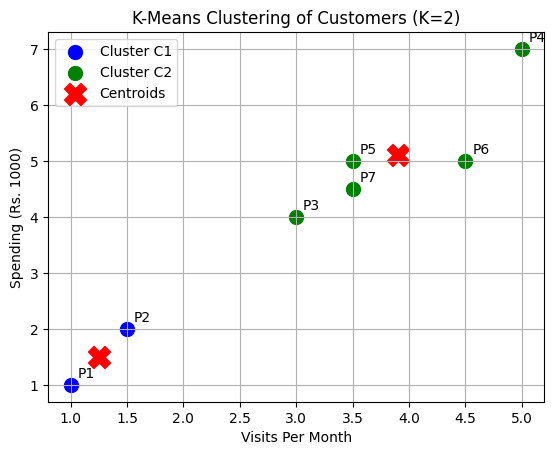

In [9]:

import matplotlib.pyplot as plt

# Plot customers belonging to Cluster C1
plt.scatter(X[final_clusters == 0, 0],
            X[final_clusters == 0, 1],
            color="blue", label="Cluster C1", s=100)

# Plot customers belonging to Cluster C2
plt.scatter(X[final_clusters == 1, 0],
            X[final_clusters == 1, 1],
            color="green", label="Cluster C2", s=100)

# Plot final centroids as red X
plt.scatter(final_centroids[:, 0],
            final_centroids[:, 1],
            color="red", marker="X", s=250,
            label="Centroids")

# Display customer labels
for i in range(len(X)):
    plt.annotate("P" + str(i + 1),
                 (X[i, 0], X[i, 1]),
                 xytext=(5, 5),
                 textcoords="offset points")

# Graph details
plt.title("K-Means Clustering of Customers (K=2)")
plt.xlabel("Visits Per Month")
plt.ylabel("Spending (Rs. 1000)")
plt.legend()
plt.grid(True)
plt.show()


In [10]:

# Select features from student marks dataset
X_students = students[["theory_marks", "practical_marks"]].values

# Display selected features
print("Student Marks Dataset:")
print(students.head(10))

print("\nTotal Number of Students:", len(students))

print("\nSelected Features:")
print(X_students)


Student Marks Dataset:
  roll_no  theory_marks  practical_marks
0     S01          36.9             40.1
1     S02          35.1             48.9
2     S03          80.2             86.3
3     S04          41.8             38.8
4     S05          89.2             79.4
5     S06          62.9             72.1
6     S07          37.4             42.9
7     S08          56.5             71.0
8     S09          38.9             40.9
9     S10          85.4             85.4

Total Number of Students: 60

Selected Features:
[[36.9 40.1]
 [35.1 48.9]
 [80.2 86.3]
 [41.8 38.8]
 [89.2 79.4]
 [62.9 72.1]
 [37.4 42.9]
 [56.5 71. ]
 [38.9 40.9]
 [85.4 85.4]
 [53.3 66.1]
 [60.3 77. ]
 [39.9 39.9]
 [66.3 72.8]
 [76.6 80.8]
 [40.4 51.8]
 [66.1 68.4]
 [66.5 71.3]
 [62.7 69.3]
 [93.  86.8]
 [82.9 87.6]
 [87.3 84.7]
 [86.2 88.1]
 [44.5 50.6]
 [83.2 91.7]
 [45.3 44.7]
 [54.3 61.2]
 [42.5 47.6]
 [87.  83.5]
 [83.1 94.5]
 [59.2 64.2]
 [40.8 43.1]
 [79.  90.4]
 [87.4 90.2]
 [43.2 47.2]
 [65.8 66.1]
 [88.3 8

K     WCSS
----------------
1     38751.65
2     10212.08
3     2204.73
4     1765.65
5     1387.83
6     1153.07
7     1015.24
8     876.06


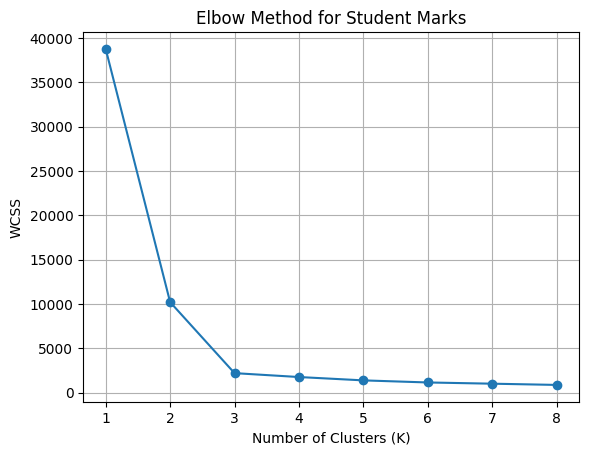

In [11]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store WCSS values
wcss = []

# Apply K-Means for K = 1 to 8
for k in range(1, 9):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_students)
    wcss.append(kmeans.inertia_)

# Display WCSS values
print("K     WCSS")
print("----------------")
for k in range(1, 9):
    print(k, "   ", round(wcss[k-1], 2))

# Plot Elbow Method
plt.plot(range(1, 9), wcss, marker='o')
plt.title("Elbow Method for Student Marks")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 9))
plt.grid(True)
plt.show()


Final Cluster Centroids:
[[84.13  86.555]
 [41.42  44.045]
 [61.045 69.12 ]]

Cluster Assignments:
Student S01 -> Cluster 1
Student S02 -> Cluster 1
Student S03 -> Cluster 0
Student S04 -> Cluster 1
Student S05 -> Cluster 0
Student S06 -> Cluster 2
Student S07 -> Cluster 1
Student S08 -> Cluster 2
Student S09 -> Cluster 1
Student S10 -> Cluster 0
Student S11 -> Cluster 2
Student S12 -> Cluster 2
Student S13 -> Cluster 1
Student S14 -> Cluster 2
Student S15 -> Cluster 0
Student S16 -> Cluster 1
Student S17 -> Cluster 2
Student S18 -> Cluster 2
Student S19 -> Cluster 2
Student S20 -> Cluster 0
Student S21 -> Cluster 0
Student S22 -> Cluster 0
Student S23 -> Cluster 0
Student S24 -> Cluster 1
Student S25 -> Cluster 0
Student S26 -> Cluster 1
Student S27 -> Cluster 2
Student S28 -> Cluster 1
Student S29 -> Cluster 0
Student S30 -> Cluster 0
Student S31 -> Cluster 2
Student S32 -> Cluster 1
Student S33 -> Cluster 0
Student S34 -> Cluster 0
Student S35 -> Cluster 1
Student S36 -> Cluster 2
S

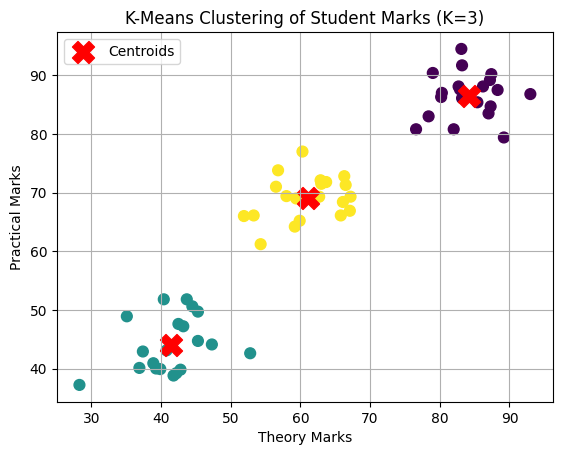

In [12]:

# Apply K-Means with optimal K = 3
kmeans_final = KMeans(n_clusters=3, random_state=42, n_init=10)

# Fit the model and predict clusters
student_clusters = kmeans_final.fit_predict(X_students)

# Get cluster centroids
student_centroids = kmeans_final.cluster_centers_

# Display results
print("Final Cluster Centroids:")
print(student_centroids)

print("\nCluster Assignments:")
for i in range(len(students)):
    print("Student", students.iloc[i]["roll_no"],
          "-> Cluster", student_clusters[i])

# Plot clusters
plt.scatter(X_students[:, 0], X_students[:, 1],
            c=student_clusters, cmap="viridis", s=60)

# Plot centroids
plt.scatter(student_centroids[:, 0],
            student_centroids[:, 1],
            color="red", marker="X", s=250,
            label="Centroids")

plt.title("K-Means Clustering of Student Marks (K=3)")
plt.xlabel("Theory Marks")
plt.ylabel("Practical Marks")
plt.legend()
plt.grid(True)
plt.show()


In [13]:

# Add cluster labels to student dataset
students["Cluster"] = student_clusters

# Calculate number of students and average marks
cluster_summary = students.groupby("Cluster").agg(
    Number_of_Students=("roll_no", "count"),
    Average_Theory_Marks=("theory_marks", "mean"),
    Average_Practical_Marks=("practical_marks", "mean")
)

# Round average marks to 2 decimal places
cluster_summary = cluster_summary.round(2)

print("Student Cluster Analysis:")
print(cluster_summary)


Student Cluster Analysis:
         Number_of_Students  Average_Theory_Marks  Average_Practical_Marks
Cluster                                                                   
0                        20                 84.13                    86.56
1                        20                 41.42                    44.04
2                        20                 61.04                    69.12


In [15]:

# Calculate overall average marks for each cluster
cluster_summary["Overall_Average"] = (
    cluster_summary["Average_Theory_Marks"] +
    cluster_summary["Average_Practical_Marks"]
) / 2

# Arrange clusters from lowest to highest average
sorted_clusters = cluster_summary.sort_values("Overall_Average").index

# Assign meaningful names
cluster_names = {
    sorted_clusters[0]: "Remedial Batch",
    sorted_clusters[1]: "Regular Batch",
    sorted_clusters[2]: "Advanced Batch"
}

# Add group names to the dataset
students["Group_Name"] = students["Cluster"].map(cluster_names)

# Display cluster names and statistics
print("Cluster Names and Performance:")
for cluster in sorted(cluster_names):
    print("\nCluster:", cluster)
    print("Group Name:", cluster_names[cluster])
    print("Number of Students:",
          cluster_summary.loc[cluster, "Number_of_Students"])
    print("Average Theory Marks:",
          cluster_summary.loc[cluster, "Average_Theory_Marks"])
    print("Average Practical Marks:",
          cluster_summary.loc[cluster, "Average_Practical_Marks"])


Cluster Names and Performance:

Cluster: 0
Group Name: Advanced Batch
Number of Students: 20
Average Theory Marks: 84.13
Average Practical Marks: 86.56

Cluster: 1
Group Name: Remedial Batch
Number of Students: 20
Average Theory Marks: 41.42
Average Practical Marks: 44.04

Cluster: 2
Group Name: Regular Batch
Number of Students: 20
Average Theory Marks: 61.04
Average Practical Marks: 69.12


In [16]:

# Marks of new student
new_student = [[70, 72]]

# Predict cluster using trained K-Means model
predicted_cluster = kmeans_final.predict(new_student)[0]

# Get corresponding group name
predicted_group = cluster_names[predicted_cluster]

# Display prediction
print("New Student Marks:")
print("Theory Marks:", new_student[0][0])
print("Practical Marks:", new_student[0][1])

print("\nPrediction Result:")
print("Predicted Cluster:", predicted_cluster)
print("Predicted Group:", predicted_group)


New Student Marks:
Theory Marks: 70
Practical Marks: 72

Prediction Result:
Predicted Cluster: 2
Predicted Group: Regular Batch
